In [10]:
import numpy as np
import matplotlib.pyplot as plt 

from scipy.fft import rfft, irfft, rfftfreq, fft2, ifft2, fftshift

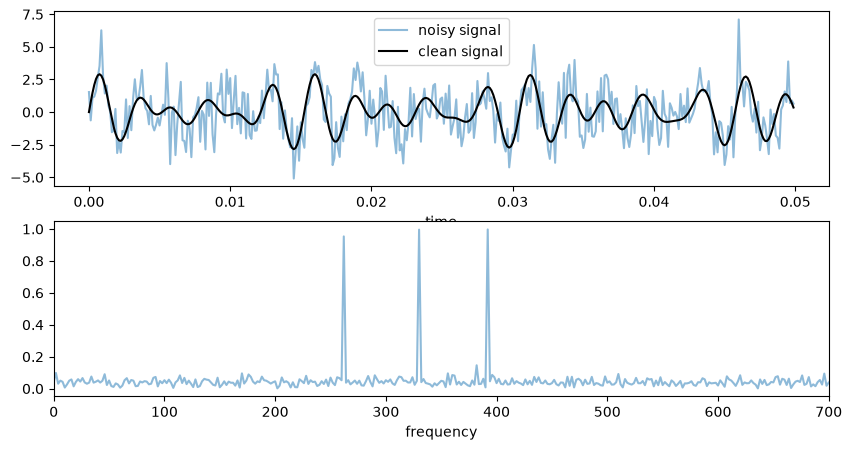

In [11]:
fs = 8000
t = np.arange(0, 0.5, 1/fs)
notes=[ 262, 330, 392]
signal = sum(np.sin(2*np.pi*t*f) for f in notes)
amp_noise = 1.5
noisy = signal + amp_noise * np.random.randn(len(t)) # np.random.normal(size=len(t))

fig, axs = plt.subplots(2,1, figsize=(10,5))
axs[0].plot(t[:400], noisy[:400], label="noisy signal", alpha=0.5)
axs[0].plot(t[:400], signal[:400], "k-", label="clean signal")
axs[0].set_xlabel("time")
axs[0].legend()

Xnoisy = rfft(noisy)
Xclean = rfft(signal)
ampnoisy = np.abs(Xnoisy) / (len(t) / 2)
ampclean = np.abs(Xclean) / (len(t) / 2)
freq = rfftfreq( len(t), 1/fs)

axs[1].plot(freq, ampnoisy, label="noisy signal", alpha=0.5)
# axs[1].plot(freq, ampclean, "--o", label = "clean signal")
axs[1].set_xlabel("frequency")
axs[1].set_xlim(0, 700)

plt.show()

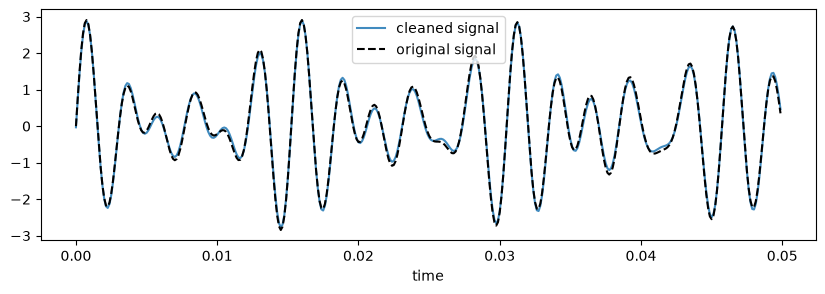

In [12]:
cutoff = np.where(np.abs(ampnoisy)> 0.25, Xnoisy, 0)
cleaned_signal = irfft(cutoff, len(t))

fig, ax = plt.subplots(figsize=(10,3))
ax.plot(t[:400], cleaned_signal[:400], label="cleaned signal", alpha=0.85)
ax.plot(t[:400], signal[:400], "k--", label="original signal")
ax.set_xlabel("time")
ax.legend()

plt.show()